# NB03B — Extensión complementaria de señales de mercado

- **Estatus:** complementario  
- **Objetivo:** construir señales de mercado laggeadas para integración con los híbridos de NB02 sin alterar el benchmark canónico.

- **Inputs mínimos:** series externas OVX/VIX/DXY/EIA, calendario de trading y `data/processed/wti_volatilidad_MODEL_BASE.csv`.  

- *Outputs principales:** `data/processed/wti_market_signals.csv`, figuras diagnósticas y actualización de `nb03b`.  

- **Config / gobernanza:** este notebook actualiza `nb03b` cuando se ejecuta la extensión activa; el benchmark canónico sigue en NB02 CPU.  
- *No inferir de este notebook:** esta extensión no redefine el ranking H0-H3 ni sustituye el benchmark central.

- **Contrato de config (runtime Colab):** NB03B usa `BASE_PATH/config_estudio_FINAL.json` como ruta real de runtime y solo actualiza `nb03b` cuando la extensión está aprobada. El archivo del repo `config/config_estudio_FINAL.json` es un espejo sincronizado después de la corrida.
  
- **Orden oficial:** `NB01 -> NB03A (si aprobado) -> NB03B (si aprobado) -> NB02 CPU -> NB02 GPU opcional`. NB03B es una rama opcional previa al cierre canónico CPU.  

- **Opt-in explícito:** `WRITE_NB03B = False` por defecto; si queda en `False`, el notebook puede exportar artefactos pero no modifica el config.


## Sección 0 — Instalación, Imports y Configuración

In [ ]:
#  0.1 Instalación
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    subprocess.run(['pip', 'install', 'yfinance', 'pandas-datareader', '-q'], check=False)
    print('[OK] yfinance instalado')
else:
    print('[INFO] Entorno local — pip install yfinance pandas-datareader')

[OK] yfinance instalado


In [ ]:
#  0.2 Imports ─
import os, sys, json, random, warnings, pickle, shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.stats as stats
from scipy.stats import spearmanr, mannwhitneyu
import requests

try:
    import yfinance as yf
    print(f'[OK] yfinance {yf.__version__}')
except ImportError:
    raise ImportError('yfinance no instalado. Ejecutar celda 0.1 primero.')

RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
print(f"RANDOM_SEED={RANDOM_SEED} | Python={sys.version.split()[0]} | seeds fijadas (sin TF en NB03B)")


[OK] yfinance 0.2.66
RANDOM_SEED=42 | Python=3.12.13 | seeds fijadas (sin TF en NB03B)


In [ ]:
#  0.3 Rutas (Colab / local)
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH   = '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos'
    NB03B_PATH  = f'{BASE_PATH}/NB03B_MarketSignals'
    FIG_PATH    = f'{NB03B_PATH}/figuras'
    CSV_MODEL_BASE = f'{BASE_PATH}/NB01_EDA/wti_volatilidad_MODEL_BASE.csv'  # backbone canonico downstream
else:
    BASE_PATH   = str(Path('..').resolve())
    NB03B_PATH  = f"{BASE_PATH}/NB03B_MarketSignals"
    FIG_PATH    = os.path.join(NB03B_PATH, 'figuras')
    CSV_MODEL_BASE = f"{BASE_PATH}/NB01_EDA/wti_volatilidad_MODEL_BASE.csv"  # backbone canonico downstream

CONFIG_RUNTIME_PATH = f"{BASE_PATH}/config_estudio_FINAL.json"
CONFIG_REPO_MIRROR = "config/config_estudio_FINAL.json"
CONFIG_PATH = CONFIG_RUNTIME_PATH
WRITE_NB03B = False   # True solo si la extensión de market signals fue aprobada para persistirse en config

os.makedirs(NB03B_PATH, exist_ok=True)
os.makedirs(FIG_PATH,   exist_ok=True)

assert os.path.exists(CONFIG_PATH), f'CONFIG no encontrado: {CONFIG_PATH}'
assert os.path.exists(CSV_MODEL_BASE), f'No encontrado: {CSV_MODEL_BASE}. Regenerar NB01 primero.'

SIGS_RAW_PATH = os.path.join(NB03B_PATH, 'market_signals_raw.csv')
EIA_RAW_PATH  = os.path.join(NB03B_PATH, 'eia_inventory_raw.csv')
OUTPUT_SIGS   = os.path.join(NB03B_PATH, 'wti_market_signals.csv')

print(f'[OK] NB03B_PATH      : {NB03B_PATH}')
print(f'[OK] CONFIG runtime : {CONFIG_RUNTIME_PATH}')
print(f'[OK] Espejo repo    : {CONFIG_REPO_MIRROR}')
print(f'[OK] WRITE_NB03B    : {WRITE_NB03B}')
print(f'[OK] CSV_MODEL_BASE : {CSV_MODEL_BASE}')
print('[INFO] NB03B es una rama opcional previa al cierre canónico de NB02 CPU.')

Mounted at /content/drive
[OK] NB03B_PATH      : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03B_MarketSignals
[OK] CONFIG runtime : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
[OK] Espejo repo    : config/config_estudio_FINAL.json
[OK] WRITE_NB03B    : False
[OK] CSV_CLEAN      : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_CLEAN.csv
[INFO] NB03B es una rama opcional previa al cierre canónico de NB02 CPU.


In [ ]:
# FIGURE_UTILS — Celda universal de importación v2.3
# Proyecto WTI Tesis | Una sola copia en cada notebook
import os, sys, warnings
import matplotlib as mpl
import matplotlib.pyplot as plt

#  Rutas candidatas (Colab → local)
for _p in [
    '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/utils',
    os.path.abspath('./utils'),
    os.path.abspath('../utils'),
]:
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

try:
    from figure_utils import (
        fig_size, save_fig, apply_thesis_style, add_top_legend,
        # Splits y clases
        SPLIT_COLORS, COLOR_NORMAL, COLOR_EXTREMO,
        # Series principales
        COLOR_PRECIO, COLOR_VOL, COLOR_CLEAN, COLOR_VAR, COLOR_DYN,
        # Percentiles y modelos
        COLORS_P, COLORES_MODELOS, COLORES_B,
        # NB03A y NB03B
        COLORS_SENT, COLORS_SIGNALS,
    )
    mpl.rcParams.update(mpl.rcParamsDefault)
    apply_thesis_style('A4')
    print("[OK] figure_utils v2.3 cargado desde utils/")

except Exception as e:
    warnings.warn(
        "[figure_utils] utils/ no disponible o falló import — activando fallback inline.\n"
        f"  Detalle: {type(e).__name__}: {e}",
        UserWarning, stacklevel=2
    )

    #  Fallback inline (espejo exacto de v2.3) ─
    def fig_size(layout='full', fmt='A4', aspect=0.618):
        tw, th = (6.11, 9.73) if fmt == 'A4' else (6.34, 9.04)
        opts = {
            'full': (tw, tw*aspect), 'half': (tw/2, (tw/2)*aspect),
            'wide': (tw, tw*0.45),   '2x1':  (tw, tw*0.50),
            '2x2':  (tw, tw*0.75),   '3x1':  (tw, tw*0.38),
            'square': (tw, tw),      'tall': (tw, min(tw*1.40, th*0.85)),
            'page': (tw, th*0.90),
            'nb03_ts':   (tw, min(tw*1.45, th*0.92)),
            'nb03_dist': (tw, tw*0.62),
            'nb03_corr': (tw, tw*0.95),
        }
        result = opts.get(layout)
        if result is None:
            warnings.warn(f"Layout '{layout}' no reconocido. Usando 'full'.", UserWarning)
            result = opts['full']
        return tuple(round(x, 4) for x in result)

    def save_fig(fig_or_none=None, filename='', output_path='.', dpi=300,
                 fmt='png', fmt_page='A4', warn=True, **kwargs):
        if not filename or not filename.strip():
            raise ValueError("filename no puede estar vacío en save_fig().")
        fig = fig_or_none if fig_or_none is not None else plt.gcf()
        os.makedirs(output_path, exist_ok=True)
        path = os.path.join(output_path,
                            f"{filename.replace(' ','_').replace('/','_')}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.04,
                    facecolor='white', edgecolor='none', **kwargs)
        w, h = fig.get_size_inches()
        print(f"  [OK] {path}  [{w:.1f}\"×{h:.1f}\" @ {dpi}dpi]")
        return path

    def add_top_legend(handles, labels=None, ax=None, fig=None,
                       ncol=4, y=0.98, fontsize=8.5, frameon=True):
        if fig is None and ax is None:
            raise ValueError("Debes pasar ax o fig.")
        kw = dict(ncol=ncol, fontsize=fontsize, frameon=frameon,
                  columnspacing=1.2, handletextpad=0.6)
        if fig is not None:
            return fig.legend(handles=handles, labels=labels,
                              loc='upper center', bbox_to_anchor=(0.5, y), **kw)
        return ax.legend(handles=handles, labels=labels,
                         loc='lower center', bbox_to_anchor=(0.5, 1.02), **kw)

    #  Paletas canónicas v2.3
    # Splits y clases
    SPLIT_COLORS  = {'train': '#2166ac', 'validation': '#f4a582',
                     'val': '#f4a582',   'test': '#d6604d'}
    COLOR_NORMAL  = '#2166ac'
    COLOR_EXTREMO = '#d73027'
    # Series principales
    COLOR_PRECIO  = '#253494'
    COLOR_VOL     = '#2c7bb6'
    COLOR_CLEAN   = '#4575b4'
    COLOR_VAR     = '#74add1'
    COLOR_DYN     = '#f4a582'
    # Percentiles
    COLORS_P      = {90: '#fdae61', 95: '#d73027', 99: '#7b2d8b'}
    # Modelos benchmark NB02
    COLORES_MODELOS = {
        'GARCH':             '#7b2d8b',
        'LSTM-Simple-Uni':   '#74add1',
        'LSTM-Simple-Multi': '#4575b4',
        'BiDir-LSTM-Uni':    '#d73027',
        'BiDir-LSTM-Multi':  '#f46d43',
        'Hybrid-Sent':       '#fdae61',
        'Hybrid-MktSignals': '#fee090',
        'Baseline-B1':       '#aaaaaa',
        'Baseline-B5':       '#555555',
    }
    # Baselines NB01
    COLORES_B     = ['#aaaaaa', '#2166ac', '#f4a582',
                     '#4575b4', '#d6604d', '#7b2d8b']
    # Sentimiento NB03A
    COLORS_SENT   = {'positive': '#1a9641', 'negative': '#d7191c', 'neutral': '#b0b0b0'}
    # Señales mercado NB03B
    COLORS_SIGNALS = {'OVX': '#d73027', 'VIX': '#4575b4',
                      'DXY': '#1a9641',  'EIA': '#7b2d8b'}

    #  Estilo IEEE fallback
    mpl.rcParams.update(mpl.rcParamsDefault)
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        pass
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Computer Modern', 'DejaVu Serif'],
        'font.size': 10,
        'axes.titlesize': 11, 'axes.titleweight': 'bold',
        'axes.titlelocation': 'center', 'axes.titlepad': 10,
        'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'xtick.major.pad': 3.5, 'ytick.major.pad': 3.5,
        'legend.fontsize': 9, 'legend.frameon': True,
        'legend.framealpha': 0.85, 'legend.edgecolor': 'gray',
        'figure.dpi': 150, 'savefig.dpi': 300,
        'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': ':',
        'axes.edgecolor': 'black', 'axes.linewidth': 0.8,
        'lines.linewidth': 1.5, 'lines.markersize': 4,
    })
    print("[OK] figure_utils fallback inline activo (v2.3)")

#  NOTA: NO definir colores adicionales después de este bloque ─
# Todas las variables canónicas ya están importadas o definidas en el fallback.
# Variables legacy eliminadas:
#   split_colors, COLORES_SPLIT, colores, COLOR_NORMAL_NB01, COLOR_EXTREMO_NB01
#   COLOR_CLEAN='#27ae60', COLOR_VAR='#8B2020', COLOR_DYN='darkorange'

[IEEE v2.3] Estilo aplicado — A4: 6.11"×9.73" (15.5×24.7 cm)
  Layouts (figsize):
    fig_size('full     ') -> (6.11, 3.78)"
    fig_size('half     ') -> (3.06, 1.89)"
    fig_size('wide     ') -> (6.11, 2.75)"
    fig_size('2x1      ') -> (6.11, 3.06)"
    fig_size('2x2      ') -> (6.11, 4.58)"
    fig_size('3x1      ') -> (6.11, 2.32)"
    fig_size('tall     ') -> (6.11, 8.27)"
    fig_size('page     ') -> (6.11, 8.76)"
    fig_size('nb03_ts  ') -> (6.11, 8.86)"
    fig_size('nb03_dist') -> (6.11, 3.79)"
    fig_size('nb03_corr') -> (6.11, 5.80)"
[OK] figure_utils v2.3 cargado desde utils/


In [ ]:
#  0.4 Cargar config + verificar test window ─
with open(CONFIG_PATH, encoding='utf-8') as f:
    config = json.load(f)

TRAIN_END  = config['fechas']['train_end']    # '2018-12-31'
VAL_START  = config['fechas']['val_start']    # '2019-01-02'
VAL_END    = config['fechas']['val_end']       # '2020-12-31'
TEST_START = config['fechas']['test_start']   # '2021-01-02'

# Guard: test_start DEBE coincidir con NB02
_EXPECTED_TEST_START = '2021-01-02'  # valor acordado inamovible (CLAUDE.md)
assert TEST_START == _EXPECTED_TEST_START, (
    f"test_start={TEST_START} != '2021-01-02' — no coincide con NB02"
)

print(f'[OK] Train:  hasta {TRAIN_END}')
print(f'[OK] Val:    {VAL_START} -> {VAL_END}')
print(f'[OK] Test:   {TEST_START} -> presente')
print(f'[OK] test_start == NB02: ✓')

[OK] Train:  hasta 2018-12-31
[OK] Val:    2019-01-02 -> 2020-12-31
[OK] Test:   2021-01-02 -> presente
[OK] test_start == NB02: ✓


In [ ]:
#  0.5 Cargar MODEL_BASE → trading_index
df_wti = pd.read_csv(CSV_MODEL_BASE, index_col='Date', parse_dates=True)  # MODEL_BASE: backbone canonico; bad_vol21 preservados con flags
df_wti.index = pd.to_datetime(df_wti.index).normalize()
trading_index = df_wti.index

df_wti['split'] = 'train'
df_wti.loc[df_wti.index >= VAL_START,  'split'] = 'validation'
df_wti.loc[df_wti.index >= TEST_START, 'split'] = 'test'

# TARGET_COL = 'is_extreme_clean' — consistencia con NB02
# NB03B es análisis de señales, no entrenamiento.
# 'y_tp1' (shift -1) no aplica aquí: la correlación Spearman
# mide señal_lag1(t) vs is_extreme_clean(t), no vs t+1.
TARGET_COL = 'is_extreme_clean'
assert TARGET_COL in df_wti.columns, (
    f"'{TARGET_COL}' no encontrada en el CSV. "
    f"Columnas disponibles: {list(df_wti.columns)}"
)

# Verificar consistencia con NB02
_p95_csv = df_wti.loc[df_wti['split'] == 'train', 'vol21_clean'].quantile(0.95)
assert abs(_p95_csv - 0.04299581565948056) < 1e-6, (
    f"P95 del CSV ({_p95_csv:.8f}) no coincide con el canónico. "
    "Regenerar wti_volatilidad_CLEAN.csv ejecutando NB01."
)

print(f'[OK] CSV_MODEL_BASE : {len(df_wti):,} filas')
print(f'     Rango        : {trading_index.min().date()} → {trading_index.max().date()}')
print(f'     TARGET_COL   : {TARGET_COL}')
print(f'     Extremos tot : {int(df_wti[TARGET_COL].sum())} '
      f'({df_wti[TARGET_COL].mean():.1%} global)')
print(f'     P95 (train)  : {_p95_csv:.8f}')

[OK] CSV_CLEAN    : 6,363 filas
     Rango        : 2000-09-22 → 2026-02-27
     TARGET_COL   : is_extreme_clean
     Extremos tot : 296 (4.7% global)
     P95 (train)  : 0.04299582


## Sección 1 — Descarga OVX, VIX, DXY (yfinance)

In [ ]:
#  1.1 Descarga con cache ─
TICKERS = {
    'OVX': '^OVX',       # CBOE Crude Oil Volatility — desde 2007-05-10
    'VIX': '^VIX',       # CBOE Volatility Index — desde 1990
    'DXY': 'DX-Y.NYB',   # US Dollar Index
}

def _normalize_index(df):
    df = df.copy()
    # Se normaliza el índice primero para evitar fallos silenciosos al validar la zona horaria.
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    df.index = df.index.normalize()
    return df

raw = pd.DataFrame() # Initialize raw as an empty DataFrame
if os.path.exists(SIGS_RAW_PATH):
    try:
        temp_raw = pd.read_csv(SIGS_RAW_PATH, index_col='Date', parse_dates=True)
        temp_raw = _normalize_index(temp_raw)
        if not temp_raw.empty:
            raw = temp_raw
            print(f'[OK] Cache: {len(raw):,} filas | {raw.index.min().date()} -> {raw.index.max().date()}')
        else:
            print(f'[WARN] Cache file empty: {SIGS_RAW_PATH}. Proceeding to download from yfinance...')
    except Exception as e:
        print(f'[ERROR] Could not read cache file: {e}. Proceeding to download from yfinance...')
else:
    print('[INFO] Cache file not found. Descargando desde yfinance...')

# Se fuerza la descarga solo si el caché no aporta datos válidos, para no arrastrar archivos vacíos o dañados.
if raw.empty:
    frames = {}
    for name, ticker in TICKERS.items():
        try:
            data = yf.download(ticker, start='2000-01-01', end='2026-03-01',
                               progress=False, auto_adjust=True)
            if data.empty:
                print(f'  [WARN] {name}: sin datos'); continue
            close = data['Close'] if 'Close' in data.columns else data.iloc[:, 0]
            # Se fuerza una Serie unidimensional para que los cálculos posteriores no dependan del formato devuelto por la API.
            # Se homogeneizan nombre e índice para que el merge posterior no dependa del proveedor.
            close = _normalize_index(close.squeeze().rename(name))
            frames[name] = close
            print(f'  [OK] {name}: {len(close):,} obs | {close.index.min().date()} -> {close.index.max().date()}')
        except Exception as ex:
            print(f'  [ERROR] {name}: {ex}')
    raw = pd.DataFrame(frames)
    if not raw.empty:
        raw.index.name = 'Date'
        raw.to_csv(SIGS_RAW_PATH)
        print(f'[OK] Cache guardado: {SIGS_RAW_PATH}')
    else:
        print('[ERROR] No data downloaded successfully. `raw` DataFrame is still empty.')

print(raw.describe().round(2))


[OK] Cache: 6,609 filas | 2000-01-03 -> 2026-02-27
           OVX      VIX      DXY
count  4731.00  6578.00  6607.00
mean     38.42    19.82    92.91
std      16.95     8.35    11.27
min      14.50     9.14    71.33
25%      29.53    14.01    82.71
50%      35.14    17.78    93.46
75%      43.53    23.17   100.26
max     325.15    82.69   120.90


In [ ]:
split_ranges = {
    'train': (pd.Timestamp('2000-01-01'), pd.Timestamp(TRAIN_END)),
    'val':   (pd.Timestamp(VAL_START),    pd.Timestamp(VAL_END)),
    'test':  (pd.Timestamp(TEST_START),   pd.Timestamp('2026-12-31')),
}
print(f'{"Señal":<8} {"Total obs":>10}  train(%)  val(%)  test(%)')
print('-' * 55)
for col in raw.columns:
    total = raw[col].notna().sum()
    pcts  = [raw.loc[(raw.index>=s)&(raw.index<=e), col].notna().mean()*100
             for s,e in split_ranges.values()]
    print(f'{col:<8} {total:>10,}  {pcts[0]:>7.1f}%  {pcts[1]:>5.1f}%  {pcts[2]:>5.1f}%')

if 'OVX' in raw.columns:
    first_ovx = raw['OVX'].first_valid_index()
    print(f'\n[INFO] OVX inicio: {first_ovx} — NaN en train 2000-{first_ovx.year-1}')
    print('       -> Opcion A (VIX+DXY+EIA) garantiza cobertura completa en train')


Señal     Total obs  train(%)  val(%)  test(%)
-------------------------------------------------------
OVX           4,731     61.0%  100.0%   99.8%
VIX           6,578     99.4%  100.0%   99.8%
DXY           6,607    100.0%  100.0%  100.0%

[INFO] OVX inicio: 2007-05-10 00:00:00 — NaN en train 2000-2006
       -> Opcion A (VIX+DXY+EIA) garantiza cobertura completa en train


## Sección 2 — Descarga EIA (Inventarios de Petróleo)

In [ ]:
#  2.1 EIA API KEY desde Colab Secrets (NUNCA hardcodear) ─
_eia_key = None

if IN_COLAB:
    try:
        from google.colab import userdata
        _eia_key = userdata.get('EIA_API_KEY')
        print('[OK] EIA_API_KEY cargada desde Colab Secrets')
    except Exception as ex:
        print(f'[WARN] No se pudo cargar EIA_API_KEY: {ex}')
        print('       Colab -> icono llave (izq) -> Agregar secreto EIA_API_KEY')
else:
    _eia_key = os.environ.get('EIA_API_KEY')
    if _eia_key:
        print('[OK] EIA_API_KEY desde variable de entorno')
    else:
        print('[WARN] EIA_API_KEY no encontrada')

EIA_KEY_AVAILABLE = _eia_key is not None and len(str(_eia_key)) > 5

[OK] EIA_API_KEY cargada desde Colab Secrets


In [ ]:
#  2.2 Descarga EIA con cache
def _download_eia_v2(api_key, series='WCRSTUS1'):
    data = None
    url  = 'https://api.eia.gov/v2/petroleum/stoc/wstk/data/'
    params = {
        'api_key': api_key, 'frequency': 'weekly',
        'data[0]': 'value', 'facets[series][]': series,
        'start': '2000-01', 'end': '2026-03', 'offset': 0, 'length': 5000,
    }
    try:
        r = requests.get(url, params=params, timeout=30)
        r.raise_for_status()
        rows = r.json().get('response', {}).get('data', [])
        if rows:
            data = pd.DataFrame(rows)
            data['Date'] = pd.to_datetime(data['period'])
            data = data.set_index('Date').sort_index()
            data['eia_inventory'] = pd.to_numeric(data['value'], errors='coerce')
            data = data[['eia_inventory']]
            print(f'  [OK] EIA v2: {len(data):,} obs')
    except Exception as ex:
        print(f'  [WARN] EIA v2: {ex}')

    if data is None:
        data2 = None
        try:
            r2 = requests.get(
                f'https://api.eia.gov/series/?api_key={api_key}&series_id={series}',
                timeout=30)
            r2.raise_for_status()
            rows2 = r2.json().get('series', [{}])[0].get('data', [])
            if rows2:
                data2 = pd.DataFrame(rows2, columns=['Date', 'eia_inventory'])
                data2['Date'] = pd.to_datetime(data2['Date'])
                data2 = data2.set_index('Date').sort_index()
                data2['eia_inventory'] = pd.to_numeric(data2['eia_inventory'], errors='coerce')
                print(f'  [OK] EIA v1 fallback: {len(data2):,} obs')
                data = data2
        except Exception as ex2:
            print(f'  [WARN] EIA v1: {ex2}')
    return data

if os.path.exists(EIA_RAW_PATH):
    eia_raw = pd.read_csv(EIA_RAW_PATH, index_col='Date', parse_dates=True)
    eia_raw.index = pd.to_datetime(eia_raw.index).normalize()
    print(f'[OK] EIA cache: {len(eia_raw):,} obs')
elif EIA_KEY_AVAILABLE:
    eia_raw = _download_eia_v2(_eia_key)
    if eia_raw is not None:
        eia_raw.index.name = 'Date'
        eia_raw.to_csv(EIA_RAW_PATH)
        print(f'[OK] EIA guardado: {EIA_RAW_PATH}')
    else:
        eia_raw = None
else:
    print('[WARN] Sin API key EIA — eia_surprise = NaN')
    eia_raw = None

[OK] EIA cache: 1,365 obs


### Nota metodológica — Frecuencia EIA y justificación de inclusión

Los inventarios EIA son de frecuencia **semanal** (publicación cada miércoles).
Se reindexan al calendario de trading con `ffill(limit=7)`: cada día hábil
de la semana recibe el valor del último reporte disponible.
La feature `eia_surprise_lag1` en el día *t* refleja la sorpresa de
inventario de la semana en curso o anterior — no una lectura diaria
independiente. Esto es práctica estándar en modelos de frecuencia mixta
(Ghysels et al., 2004).

**Justificación de inclusión:** las desviaciones de inventario respecto a la
media histórica generan shocks de precio del crudo (Kilian, 2009; Ye et al.,
2002), los cuales son condición necesaria — aunque no suficiente — para
eventos de volatilidad extrema (vol21 > P95). La relación inventario →
volatilidad extrema es indirecta y su valor predictivo se evalúa
empíricamente en el benchmark (NB02 Parte V).

**Limitación explícita:** esta cadena causal no ha sido validada
específicamente en literatura de clasificación de extremos en commodities.

## Sección 3 — Feature Engineering

In [ ]:
#  3.1 Alinear al trading_index
# FIX TIMEZONE: normalizar ANTES del reindex
daily = raw.copy()
daily.index = pd.to_datetime(daily.index).normalize()
if daily.index.tz is not None:
    daily.index = daily.index.tz_localize(None)

daily = daily.reindex(trading_index)
daily = daily.ffill(limit=5)

print(f'[OK] Señales alineadas: {len(daily):,} filas')
for col in daily.columns:
    n_nan = daily[col].isna().sum()
    print(f'  {col}: {n_nan:,} NaN ({n_nan/len(daily)*100:.1f}%)')

[OK] Señales alineadas: 6,363 filas
  OVX: 1,654 NaN (26.0%)
  VIX: 0 NaN (0.0%)
  DXY: 0 NaN (0.0%)


In [ ]:
#  3.2 Features estacionarias
# REGLA: SOLO retornos log y z-scores — NO niveles absolutos
signals = pd.DataFrame(index=trading_index)

if 'OVX' in daily.columns and daily['OVX'].notna().sum() > 100:
    signals['ovx_ret']    = np.log(daily['OVX'] / daily['OVX'].shift(1))
    signals['ovx_zscore'] = (
        (daily['OVX'] - daily['OVX'].rolling(252, min_periods=63).mean()) /
        daily['OVX'].rolling(252, min_periods=63).std()
    )
    print('[OK] OVX: ovx_ret, ovx_zscore')

if 'VIX' in daily.columns and daily['VIX'].notna().sum() > 100:
    signals['vix_ret'] = np.log(daily['VIX'] / daily['VIX'].shift(1))
    print('[OK] VIX: vix_ret')

if 'DXY' in daily.columns and daily['DXY'].notna().sum() > 100:
    signals['dxy_ret'] = np.log(daily['DXY'] / daily['DXY'].shift(1))
    print('[OK] DXY: dxy_ret')

if eia_raw is not None:
    eia = eia_raw.copy()
    eia.index = pd.to_datetime(eia.index).normalize()
    if eia.index.tz is not None:
        eia.index = eia.index.tz_localize(None)
    eia_daily = eia['eia_inventory'].reindex(trading_index).ffill(limit=7)
    # min_periods=52: EIA es semanal -> 52 semanas = 1 anio de warm-up para estimar media/std robusta
    rolling_mean = eia_daily.rolling(252, min_periods=52).mean()
    rolling_std  = eia_daily.rolling(252, min_periods=52).std()
    signals['eia_surprise'] = (eia_daily - rolling_mean) / rolling_std.replace(0, np.nan)
    print('[OK] EIA: eia_surprise')
else:
    signals['eia_surprise'] = np.nan
    print('[WARN] EIA sin datos — eia_surprise = NaN')

BASE_SIGNALS = list(signals.columns)
print(f'\nFeatures base: {BASE_SIGNALS}')
print(signals.describe().round(4))

[OK] OVX: ovx_ret, ovx_zscore
[OK] VIX: vix_ret
[OK] DXY: dxy_ret
[OK] EIA: eia_surprise

Features base: ['ovx_ret', 'ovx_zscore', 'vix_ret', 'dxy_ret', 'eia_surprise']
         ovx_ret  ovx_zscore    vix_ret    dxy_ret  eia_surprise
count  4708.0000   4647.0000  6362.0000  6362.0000     6254.0000
mean      0.0002     -0.0041    -0.0000    -0.0000        0.2244
std       0.0549      1.3831     0.0722     0.0049        1.3650
min      -0.4399     -3.7444    -0.4424    -0.0272       -3.3834
25%      -0.0281     -0.9237    -0.0400    -0.0028       -0.8930
50%      -0.0036     -0.3032    -0.0057     0.0000        0.3164
75%       0.0245      0.5551     0.0335     0.0027        1.2075
max       0.6361     10.2563     0.7682     0.0252        4.0147


**Nota metodológica — frecuencia EIA:**  
Los inventarios EIA son semanales (publicación cada miércoles).
Se reindexan al calendario de trading con `ffill(limit=7)`:cada día de la semana recibe el valor del último reporte disponible.  
La feature `eia_surprise_lag1` en el día t refleja por tanto la sorpresa de inventario de la semana en curso (o anterior), no una lectura diaria independiente. Esto es práctica estándar en modelos de frecuencia mixta  
(véase Ghysels et al., 2004 — MIDAS regression).

In [ ]:
#  3.3 Features lag1 (ANTI-LEAKAGE obligatorio)
# lag1 = shift(1) = valor del DÍA ANTERIOR al día a predecir
for col in BASE_SIGNALS:
    signals[f'{col}_lag1'] = signals[col].shift(1)

FEATURES_MODEL_LAG1 = [f'{c}_lag1' for c in BASE_SIGNALS]

print(f'[OK] Features base:   {BASE_SIGNALS}')
print(f'[OK] Features modelo: {FEATURES_MODEL_LAG1}')
print('\nPrimeras 3 filas de lag1 (fila 0 debe ser NaN):')
print(signals[FEATURES_MODEL_LAG1].head(3).round(4))

[OK] Features base:   ['ovx_ret', 'ovx_zscore', 'vix_ret', 'dxy_ret', 'eia_surprise']
[OK] Features modelo: ['ovx_ret_lag1', 'ovx_zscore_lag1', 'vix_ret_lag1', 'dxy_ret_lag1', 'eia_surprise_lag1']

Primeras 3 filas de lag1 (fila 0 debe ser NaN):
            ovx_ret_lag1  ovx_zscore_lag1  vix_ret_lag1  dxy_ret_lag1  \
Date                                                                    
2000-09-22           NaN              NaN           NaN           NaN   
2000-09-25           NaN              NaN           NaN           NaN   
2000-09-26           NaN              NaN        0.0318        0.0044   

            eia_surprise_lag1  
Date                           
2000-09-22                NaN  
2000-09-25                NaN  
2000-09-26                NaN  


In [ ]:
signals['split'] = df_wti['split']

print('=== Cobertura features lag1 por split (% no-NaN) ===')
for sp in ['train', 'validation', 'test']:
    sub = signals[signals['split'] == sp][FEATURES_MODEL_LAG1]
    print(f'  {sp} ({len(sub):,} obs):')
    for col in FEATURES_MODEL_LAG1:
        pct = sub[col].notna().mean() * 100
        print(f'    {col:<25}: {pct:5.1f}%')
    print()

signals = signals.drop(columns=['split'])

if 'ovx_ret_lag1' in FEATURES_MODEL_LAG1:
    train_mask = df_wti['split'] == 'train'
    pct_ovx = signals.loc[train_mask, 'ovx_ret_lag1'].notna().mean() * 100
    if pct_ovx < 60:
        print(f'[WARN] ovx_ret_lag1: {pct_ovx:.1f}% en train')
        print('       Recomendar Opcion A (sin OVX) para comparabilidad con NB02')


=== Cobertura features lag1 por split (% no-NaN) ===
  train (4,584 obs):
    ovx_ret_lag1             :  63.9%
    ovx_zscore_lag1          :  62.5%
    vix_ret_lag1             : 100.0%
    dxy_ret_lag1             : 100.0%
    eia_surprise_lag1        :  97.9%

  validation (483 obs):
    ovx_ret_lag1             : 100.0%
    ovx_zscore_lag1          : 100.0%
    vix_ret_lag1             : 100.0%
    dxy_ret_lag1             : 100.0%
    eia_surprise_lag1        :  99.4%

  test (1,296 obs):
    ovx_ret_lag1             : 100.0%
    ovx_zscore_lag1          : 100.0%
    vix_ret_lag1             : 100.0%
    dxy_ret_lag1             : 100.0%
    eia_surprise_lag1        :  99.2%



## Sección 4 — Validación Anti-Leakage

In [ ]:
#  4.1 Assert: todas las features terminan en _lag1
print('=== Check 4.1: features terminan en _lag1 ===')
for col in FEATURES_MODEL_LAG1:
    assert col.endswith('_lag1'), f'LEAKAGE: feature "{col}" NO termina en _lag1'
    print(f'  [OK] {col}')
print('[OK] 4.1 pasado\n')

#  4.2 Assert: lag1 == shift(1) exacto
print('=== Check 4.2: lag1 == shift(1) exacto ===')
for col in BASE_SIGNALS:
    lag_col  = signals[f'{col}_lag1'].dropna()
    base_col = signals[col].shift(1).dropna()
    common   = lag_col.index.intersection(base_col.index)
    if len(common) > 10:
        diff = (lag_col[common] - base_col[common]).abs().max()
        assert diff < 1e-10, f'LEAKAGE: {col}_lag1 != shift(1). diff={diff:.2e}'
        print(f'  [OK] {col}_lag1 == shift(1). max_diff={diff:.2e}')
print('[OK] 4.2 pasado\n')

#  4.3 Assert: primera fila lag1 es NaN
print('=== Check 4.3: primera fila lag1 == NaN ===')
for col in FEATURES_MODEL_LAG1:
    first_val = signals[col].iloc[0]
    assert pd.isna(first_val), f'LEAKAGE: {col}.iloc[0] = {first_val}'
    print(f'  [OK] {col}.iloc[0] = NaN')
print('[OK] 4.3 pasado\n')

#  4.4 Assert: índice monotónico creciente
print('=== Check 4.4: índice monotónico ===')
assert signals.index.is_monotonic_increasing, 'LEAKAGE: índice NO es monotónico'
print(f'  [OK] {signals.index.min().date()} -> {signals.index.max().date()}')
print('[OK] 4.4 pasado\n')

=== Check 4.1: features terminan en _lag1 ===
  [OK] ovx_ret_lag1
  [OK] ovx_zscore_lag1
  [OK] vix_ret_lag1
  [OK] dxy_ret_lag1
  [OK] eia_surprise_lag1
[OK] 4.1 pasado

=== Check 4.2: lag1 == shift(1) exacto ===
  [OK] ovx_ret_lag1 == shift(1). max_diff=0.00e+00
  [OK] ovx_zscore_lag1 == shift(1). max_diff=0.00e+00
  [OK] vix_ret_lag1 == shift(1). max_diff=0.00e+00
  [OK] dxy_ret_lag1 == shift(1). max_diff=0.00e+00
  [OK] eia_surprise_lag1 == shift(1). max_diff=0.00e+00
[OK] 4.2 pasado

=== Check 4.3: primera fila lag1 == NaN ===
  [OK] ovx_ret_lag1.iloc[0] = NaN
  [OK] ovx_zscore_lag1.iloc[0] = NaN
  [OK] vix_ret_lag1.iloc[0] = NaN
  [OK] dxy_ret_lag1.iloc[0] = NaN
  [OK] eia_surprise_lag1.iloc[0] = NaN
[OK] 4.3 pasado

=== Check 4.4: índice monotónico ===
  [OK] 2000-09-22 -> 2026-02-27
[OK] 4.4 pasado



In [ ]:
print('=== Check 4.5: Correlación Spearman con target ===\n')
for sp in ['train', 'validation', 'test']:
    mask    = df_wti['split'] == sp
    y_split = df_wti.loc[mask, TARGET_COL]
    print(f'  {sp} ({mask.sum():,} obs, extremos={y_split.sum():.0f}):')
    for col in FEATURES_MODEL_LAG1:
        x_split = signals.loc[mask, col]
        common  = x_split.notna() & y_split.notna()
        if common.sum() < 20 or y_split[common].std() == 0:
            continue
        r, p = spearmanr(x_split[common], y_split[common])
        sig  = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
        print(f'    {col:<25}: r={r:+.4f} p={p:.4f} {sig}')
    print()

if 'vix_ret_lag1' in FEATURES_MODEL_LAG1:
    mask_t  = df_wti['split'] == 'test'
    x_boot  = signals.loc[mask_t, 'vix_ret_lag1'].dropna()
    y_boot  = df_wti.loc[x_boot.index, TARGET_COL]
    common  = x_boot.index.intersection(y_boot.dropna().index)
    if len(common) >= 20:
        np.random.seed(RANDOM_SEED)
        boot_r = []
        for _ in range(1000):
            idx = np.random.choice(len(common), len(common), replace=True)
            r_b, _ = spearmanr(x_boot[common].iloc[idx], y_boot[common].iloc[idx])
            boot_r.append(r_b)
        ic_lo, ic_hi = np.percentile(boot_r, [2.5, 97.5])
        r_obs, _ = spearmanr(x_boot[common], y_boot[common])
        print(f'Bootstrap IC95% vix_ret_lag1 (test): r={r_obs:+.4f} IC=[{ic_lo:+.4f}, {ic_hi:+.4f}]')
        print(f'  (NB03 sentimiento: r=0.009 IC[-0.052,+0.046])')


=== Check 4.5: Correlación Spearman con target ===

  train (4,584 obs, extremos=230):
    ovx_ret_lag1             : r=-0.0160 p=0.3871 
    ovx_zscore_lag1          : r=+0.3233 p=0.0000 ***
    vix_ret_lag1             : r=-0.0163 p=0.2695 
    dxy_ret_lag1             : r=+0.0157 p=0.2871 
    eia_surprise_lag1        : r=+0.1817 p=0.0000 ***

  validation (483 obs, extremos=39):
    ovx_ret_lag1             : r=-0.0268 p=0.5566 
    ovx_zscore_lag1          : r=+0.4386 p=0.0000 ***
    vix_ret_lag1             : r=-0.0587 p=0.1978 
    dxy_ret_lag1             : r=-0.0132 p=0.7716 
    eia_surprise_lag1        : r=+0.1480 p=0.0011 **

  test (1,296 obs, extremos=27):
    ovx_ret_lag1             : r=-0.0548 p=0.0486 *
    ovx_zscore_lag1          : r=+0.2197 p=0.0000 ***
    vix_ret_lag1             : r=-0.0512 p=0.0654 
    dxy_ret_lag1             : r=+0.0208 p=0.4540 
    eia_surprise_lag1        : r=-0.1087 p=0.0001 ***

Bootstrap IC95% vix_ret_lag1 (test): r=-0.0512 IC=[-0.102

In [ ]:
from statsmodels.tsa.stattools import adfuller

print('=== Check 4.6: ADF en train ===')
print(f'  {"Feature":<25} {"p-ADF":>8}  {"Estacionaria":>14}')
print('  ' + '-' * 52)
train_mask = df_wti['split'] == 'train'
for col in BASE_SIGNALS:
    x = signals.loc[train_mask, col].dropna()
    if len(x) < 50:
        print(f'  {col:<25} {"N/A":>8}  {"n insuf":>14}'); continue
    try:
        p_adf = adfuller(x, autolag='AIC')[1]
        stat  = 'SI (p<0.05)' if p_adf < 0.05 else 'NO - revisar'
        print(f'  {col:<25} {p_adf:>8.4f}  {stat:>14}')
    except Exception as ex:
        print(f'  {col:<25} {"ERROR":>8}  {str(ex)[:14]:>14}')
print('[OK] 4.6 pasado\n')

#  4.7 Marcar checks ─
LEAKAGE_CHECKS_PASSED = True
print('[OK] LEAKAGE_CHECKS_PASSED = True')
print('     Checks completados: 4.1, 4.2, 4.3, 4.4, 4.5, 4.6')


=== Check 4.6: ADF en train ===
  Feature                      p-ADF    Estacionaria
  ----------------------------------------------------
  ovx_ret                     0.0000     SI (p<0.05)
  ovx_zscore                  0.0011     SI (p<0.05)
  vix_ret                     0.0000     SI (p<0.05)
  dxy_ret                     0.0000     SI (p<0.05)
  eia_surprise                0.0000     SI (p<0.05)
[OK] 4.6 pasado

[OK] LEAKAGE_CHECKS_PASSED = True
     Checks completados: 4.1, 4.2, 4.3, 4.4, 4.5, 4.6


## Sección 5 — EDA y Figuras

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03B_MarketSignals/figuras/fig_nb03b_01_signals.png  [6.1"×8.3" @ 300dpi]


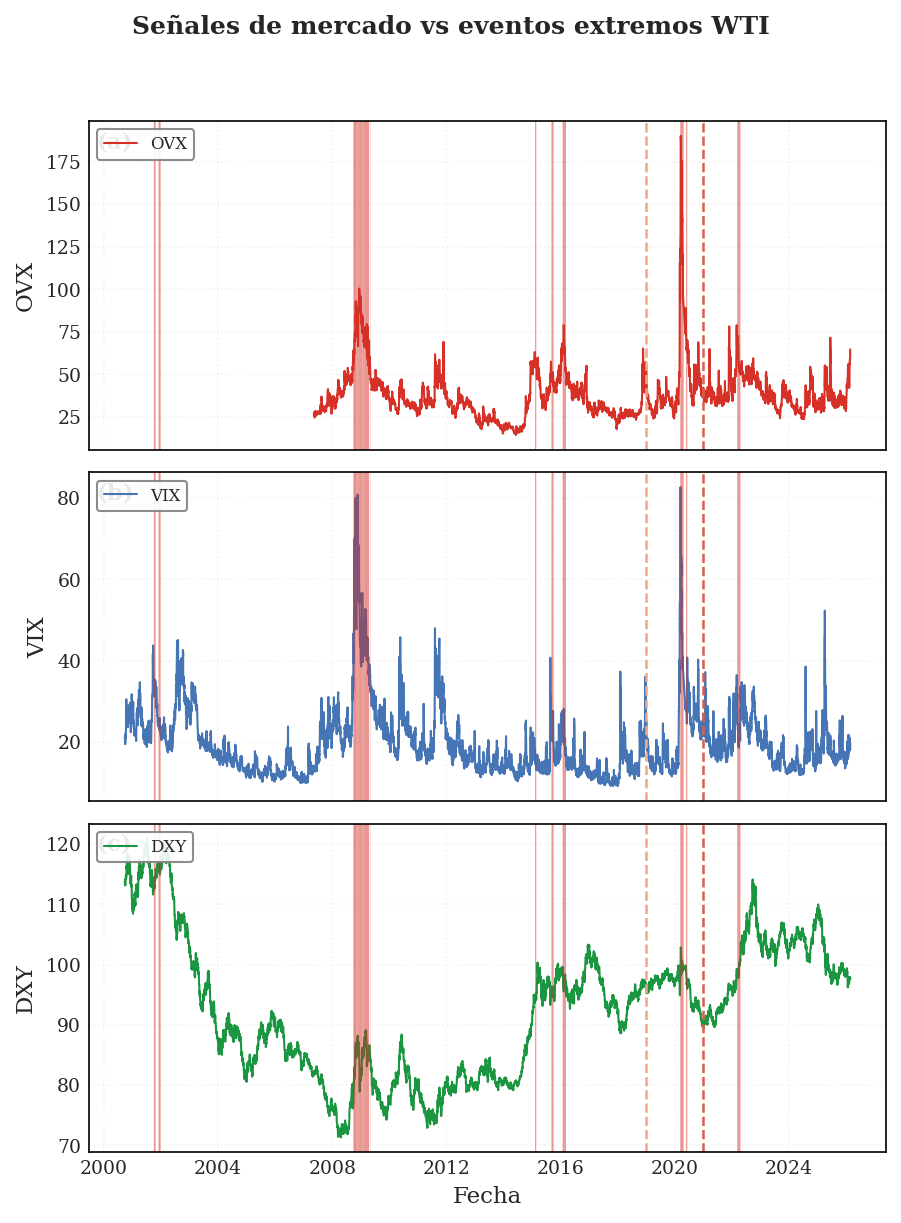

[OK] Fig 5.1 IEEE A4 guardada


In [ ]:
extreme_dates = df_wti[df_wti[TARGET_COL] == 1].index
plot_cols = [c for c in ['OVX', 'VIX', 'DXY'] if c in raw.columns]

if plot_cols:
    colors = {k: COLORS_SIGNALS[k] for k in plot_cols if k in COLORS_SIGNALS}

    fig, axes = plt.subplots(len(plot_cols), 1,
                            figsize=fig_size('tall'),
                            sharex=True)
    if len(plot_cols) == 1:
        axes = [axes]

    panel_labels = ['(a)', '(b)', '(c)']
    for i_ax, (ax, col) in enumerate(zip(axes, plot_cols)):
        ax.plot(daily.index, daily[col].values,
                color=colors.get(col, COLOR_VAR), lw=1.0, label=col)

        for ed in extreme_dates:
            ax.axvline(ed, color=COLOR_EXTREMO, alpha=0.07, lw=0.5)

        ax.axvline(pd.Timestamp(TRAIN_END),  color=SPLIT_COLORS['validation'], lw=1.2, ls='--')
        ax.axvline(pd.Timestamp(TEST_START), color=SPLIT_COLORS['test'], lw=1.2, ls='--')

        ax.set_ylabel(col, fontsize=11)
        ax.text(0.01, 0.97, panel_labels[i_ax], transform=ax.transAxes,
                fontsize=11, fontweight='bold', va='top')
        ax.legend(loc='upper left', fontsize=8, framealpha=0.9)

    axes[-1].set_xlabel('Fecha', fontsize=11)
    fig.suptitle('Señales de mercado vs eventos extremos WTI',
                 fontweight='bold', fontsize=12, y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    save_fig(fig, 'fig_nb03b_01_signals', output_path=FIG_PATH, dpi=300)
    plt.show()
    plt.close()
    print('[OK] Fig 5.1 IEEE A4 guardada')


**Qué muestra**  
Esta figura presenta la evolución temporal de las señales de mercado externas junto con la ocurrencia de eventos extremos del WTI. Cada panel corresponde a una señal base utilizada como insumo exógeno potencial.

**Cómo se construye**  
Se construye graficando cada serie diaria sobre su propio eje y superponiendo líneas verticales para los eventos extremos y los cortes temporales del estudio. La paleta se alinea con las convenciones canónicas del proyecto para cada señal.

**Por qué se ve así**  
La disposición vertical separa escalas heterogéneas y evita mezclar magnitudes no comparables en un solo panel. Las líneas de eventos aparecen atenuadas para conservar contexto sin saturar la lectura de las trayectorias principales.

**Por qué es importante**  
Esta figura permite verificar visualmente si las señales exógenas cambian en torno a episodios de estrés del mercado petrolero. También deja trazable qué insumos se exportan a NB02 para los modelos híbridos y multivariados.

In [ ]:
#  5.2 Distribución extremos vs normales (test set)
print("=== Mann-Whitney + Cohen's d (test set) ===\n")
mask_test = df_wti['split'] == 'test'
y_test    = df_wti.loc[mask_test, TARGET_COL]

for col in FEATURES_MODEL_LAG1:
    x_test = signals.loc[mask_test, col]
    valid  = x_test.notna() & y_test.notna()
    if valid.sum() < 20: continue
    x_ext  = x_test[valid & (y_test == 1)]
    x_norm = x_test[valid & (y_test == 0)]
    if len(x_ext) < 5 or len(x_norm) < 5: continue
    stat, p_mw = mannwhitneyu(x_ext, x_norm, alternative='two-sided')
    n1, n2 = len(x_ext), len(x_norm)
    s_pool = np.sqrt(((n1-1)*x_ext.std()**2 + (n2-1)*x_norm.std()**2) / (n1+n2-2))
    d = (x_ext.mean() - x_norm.mean()) / (s_pool + 1e-9)
    print(f'  {col:<25} p={p_mw:.4f} d={d:+.4f} '
          f'(ext={x_ext.mean():+.4f}|norm={x_norm.mean():+.4f})')
print('\n  [INFO] |d|>0.2 peq | |d|>0.5 med | |d|>0.8 grande')

=== Mann-Whitney + Cohen's d (test set) ===

  ovx_ret_lag1              p=0.0487 d=-0.2698 (ext=-0.0160|norm=+0.0007)
  ovx_zscore_lag1           p=0.0000 d=+2.0382 (ext=+2.1267|norm=-0.1715)
  vix_ret_lag1              p=0.0655 d=-0.2487 (ext=-0.0190|norm=+0.0002)
  dxy_ret_lag1              p=0.4540 d=+0.0349 (ext=+0.0002|norm=+0.0001)
  eia_surprise_lag1         p=0.0001 d=-0.8424 (ext=-1.5809|norm=-0.5153)

  [INFO] |d|>0.2 peq | |d|>0.5 med | |d|>0.8 grande


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03B_MarketSignals/figuras/fig_nb03b_02_corr.png  [6.1"×5.8" @ 300dpi]


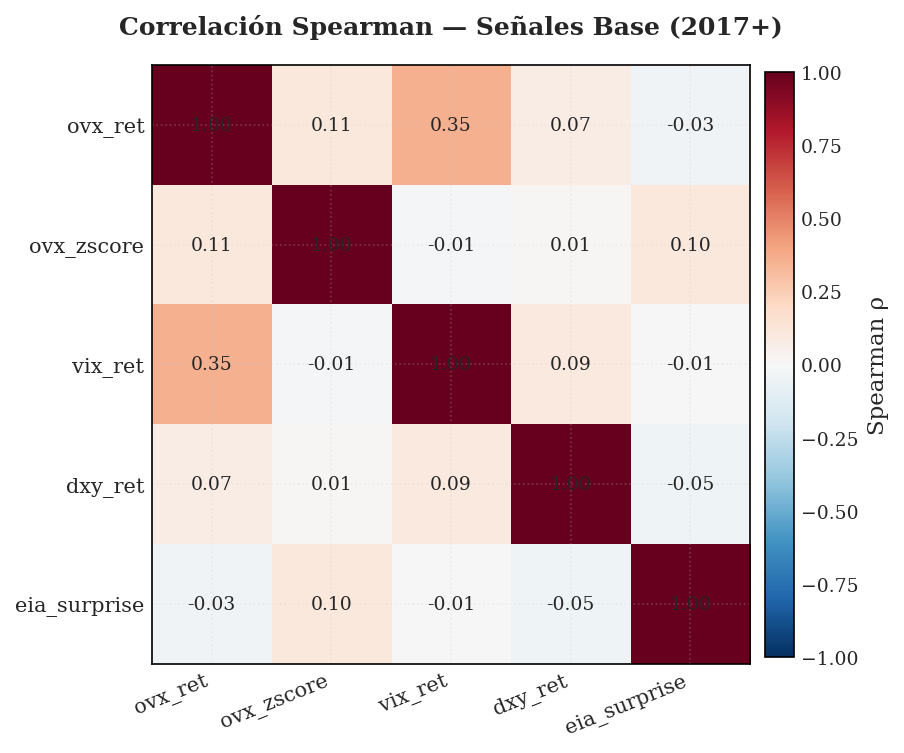

[OK] Fig 5.3 IEEE A4 guardada


In [ ]:
#  5.3 Correlación Spearman filtrada a 2017+
mask_2017 = signals.index >= pd.Timestamp('2017-01-01')
sigs_2017 = signals.loc[mask_2017, BASE_SIGNALS].dropna(how='all')

if len(sigs_2017) > 50 and sigs_2017.shape[1] > 1:
    corr_m = sigs_2017.corr(method='spearman')

    fig, ax = plt.subplots(figsize=fig_size('nb03_corr'))  # ← 6.11"x5.80" A4

    im = ax.imshow(corr_m, cmap='RdBu_r', vmin=-1, vmax=1)
    plt.colorbar(im, ax=ax, label='Spearman ρ', shrink=0.75, pad=0.02)

    cols = list(corr_m.columns)
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=22, ha='right', fontsize=10)
    ax.set_yticklabels(cols, fontsize=10)

    # Números centrados IEEE
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f'{corr_m.iloc[i,j]:.2f}',
                   ha='center', va='center', fontsize=9)

    ax.set_title('Correlación Spearman — Señales Base (2017+)',
                fontweight='bold', fontsize=12, pad=15)

    plt.tight_layout()

    save_fig(fig, 'fig_nb03b_02_corr', output_path=FIG_PATH, dpi=300)
    plt.show()
    plt.close()
    print('[OK] Fig 5.3 IEEE A4 guardada')


## Sección 6 — Exportación y Actualización de Config

In [ ]:
#  6.1 Construir CSV final ─
export_cols = BASE_SIGNALS + FEATURES_MODEL_LAG1
df_export   = signals[export_cols].copy()
df_export.index.name = 'Date'

assert df_export.index.is_monotonic_increasing, 'LEAKAGE: índice NO monotónico'
assert df_export.shape[0] == len(trading_index), (
    f'Mismatch: {df_export.shape[0]} != {len(trading_index)}')

print(f'[OK] CSV: {df_export.shape[0]:,} filas x {df_export.shape[1]} cols')
print(f'     Columnas: {list(df_export.columns)}')
print(df_export.describe().round(4))

[OK] CSV: 6,363 filas x 10 cols
     Columnas: ['ovx_ret', 'ovx_zscore', 'vix_ret', 'dxy_ret', 'eia_surprise', 'ovx_ret_lag1', 'ovx_zscore_lag1', 'vix_ret_lag1', 'dxy_ret_lag1', 'eia_surprise_lag1']
         ovx_ret  ovx_zscore    vix_ret    dxy_ret  eia_surprise  \
count  4708.0000   4647.0000  6362.0000  6362.0000     6254.0000   
mean      0.0002     -0.0041    -0.0000    -0.0000        0.2244   
std       0.0549      1.3831     0.0722     0.0049        1.3650   
min      -0.4399     -3.7444    -0.4424    -0.0272       -3.3834   
25%      -0.0281     -0.9237    -0.0400    -0.0028       -0.8930   
50%      -0.0036     -0.3032    -0.0057     0.0000        0.3164   
75%       0.0245      0.5551     0.0335     0.0027        1.2075   
max       0.6361     10.2563     0.7682     0.0252        4.0147   

       ovx_ret_lag1  ovx_zscore_lag1  vix_ret_lag1  dxy_ret_lag1  \
count     4707.0000        4646.0000     6361.0000     6361.0000   
mean         0.0002          -0.0049       -0.0000  

In [ ]:
#  6.2 Guardar wti_market_signals.csv
df_export.to_csv(OUTPUT_SIGS)
_reload = pd.read_csv(OUTPUT_SIGS, index_col='Date', parse_dates=True)
assert _reload.shape == df_export.shape, 'Error al recargar CSV'
print(f'[OK] Guardado y verificado: {OUTPUT_SIGS}')
print(f'     {df_export.shape[0]:,} filas x {df_export.shape[1]} columnas')

[OK] Guardado y verificado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03B_MarketSignals/wti_market_signals.csv
     6,363 filas x 10 columnas


In [ ]:
# --- 6.3 Actualizar config_estudio_FINAL.json -> clave nb03b (opt-in)
if not WRITE_NB03B:
    print('[SKIP] WRITE_NB03B=False -> nb03b no se actualiza en el config.')
    print(f'       Config runtime intacto: {CONFIG_PATH}')
    print(f'       Espejo repo esperado : {CONFIG_REPO_MIRROR}')
else:
    with open(CONFIG_PATH, encoding='utf-8') as f:
        config_out = json.load(f)

    cob = {}
    for sp in ['train', 'validation', 'test']:
        mask_sp = df_wti['split'] == sp
        cob[sp] = {
            col: round(float(signals.loc[mask_sp, col].notna().mean()), 4)
            for col in FEATURES_MODEL_LAG1
        }

    has_ovx = ('ovx_ret_lag1' in FEATURES_MODEL_LAG1 and
               signals['ovx_ret_lag1'].notna().sum() > 100)
    opcion = 'B' if has_ovx else 'A'
    nb02_test_start = TEST_START
    NB03B_OUTPUT_CSV = 'data/processed/wti_market_signals.csv'
    NB03B_FUENTES = {
        'OVX': 'CBOE Crude Oil Volatility Index (^OVX) - yfinance, desde 2007-05-10',
        'VIX': 'CBOE Volatility Index (^VIX) - yfinance, desde 1990',
        'DXY': 'US Dollar Index (DX-Y.NYB) - yfinance',
        'EIA': 'EIA Weekly Petroleum Status Report (WCRSTUS1) - api.eia.gov'
    }

    config_out['nb03b'] = {
        'fecha_ejecucion': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'tipo': 'market_signals',
        'fuentes': NB03B_FUENTES,
        'features_base': list(BASE_SIGNALS),
        'features_modelo': list(FEATURES_MODEL_LAG1),
        'features_excluidas_no_estacionarias': ['ovx_level', 'vix_level'],
        'opcion_features_hybrid_seleccionada': opcion,
        'nota_opcion_A': 'VIX+DXY+EIA - cobertura completa 2000-2026, train ~4300 obs',
        'nota_opcion_B': 'OVX+VIX+EIA - OVX desde 2007, train ~2500 obs (reduccion 42%)',
        'eia_role': 'auxiliary_structured_signal - sorpresa inventario crudo EEUU.',
        'cobertura_split': cob,
        'signals_usable': bool(LEAKAGE_CHECKS_PASSED),
        'leakage_checks_passed': bool(LEAKAGE_CHECKS_PASSED),
        'split_validation_vs_nb02': {
            'test_start_nb02': nb02_test_start,
            'test_start_nb03b': TEST_START,
            'match': TEST_START == nb02_test_start
        },
        'razon_descarte_nb03_finbert': (
            'r_Spearman=0.009, IC95%=[-0.052,+0.046]. Sin poder predictivo en ningun split.'
        ),
        'advertencias': [
            'Usar SOLO columnas *_lag1 en NB02',
            'OVX introduce NaN 2000-2007 si se usa Opcion B',
            'Opcion A garantiza comparabilidad directa con NB02'
        ],
        'output_csv': NB03B_OUTPUT_CSV
    }

    import shutil
    tmp_path = CONFIG_PATH + '.tmp'
    with open(tmp_path, 'w', encoding='utf-8') as f:
        json.dump(config_out, f, ensure_ascii=False, indent=2)
    shutil.move(tmp_path, CONFIG_PATH)
    print('[OK] Config actualizado con clave nb03b')
    print(f'     opcion={opcion} | signals_usable={bool(LEAKAGE_CHECKS_PASSED)}')
    print(f'     test_start_nb02={nb02_test_start} | test_start_nb03b={TEST_START}')
    print(f'     output_csv={NB03B_OUTPUT_CSV}')
    print('[INFO] NB03B actualiza solo nb03b; no toca nb02_results ni nb02_experiments.')

[SKIP] WRITE_NB03B=False -> nb03b no se actualiza en el config.
       Config runtime intacto: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
       Espejo repo esperado : config/config_estudio_FINAL.json


In [ ]:
def _pick(*names, default='No disponible'):
    for name in names:
        if name in globals() and globals()[name] is not None:
            return globals()[name]
    return default

_cfg_nb03b = {}
if 'config' in globals() and isinstance(config, dict):
    _cfg_nb03b = config.get('nb03b', {})
elif 'config_base' in globals() and isinstance(config_base, dict):
    _cfg_nb03b = config_base.get('nb03b', {})

_features_model = _pick(
    'FEATURES_MODEL_LAG1',
    'features_modelo',
    'market_features',
    default=_cfg_nb03b.get('features_modelo', 'No disponible')
)

_opcion_activa = _pick(
    'opcion',
    'OPTION_SELECTED',
    default=_cfg_nb03b.get('opcion_features_hybrid_seleccionada', 'No disponible')
)

_leakage_ok = _pick(
    'LEAKAGE_CHECKS_PASSED',
    'leakage_checks_passed',
    default=_cfg_nb03b.get('leakage_checks_passed', 'No disponible')
)

_test_start = _pick(
    'TEST_START',
    'test_start_date',
    default=_cfg_nb03b.get('split_validation_vs_nb02', {}).get('test_start_nb03b', 'No disponible')
)

print('  NB03B - RESUMEN FINAL (extension complementaria)')
print('  CSV canonico del repo: data/processed/wti_market_signals.csv')
print(f'  Features modelo: {_features_model}')
print(f'  Opcion activa: {_opcion_activa}')
print(f'  LEAKAGE_CHECKS_PASSED: {_leakage_ok}')
print(f'  test_start = {_test_start}')
print()
print('Integracion con NB02:')
print('  -> Consumir el CSV y el contrato documentado en config["nb03b"]')
print('  -> Usar SOLO columnas *_lag1')
print('  -> Mantener StandardScaler con fit SOLO en train')

  NB03B - RESUMEN FINAL (extension complementaria)
  CSV canonico del repo: data/processed/wti_market_signals.csv
  Features modelo: ['ovx_ret_lag1', 'ovx_zscore_lag1', 'vix_ret_lag1', 'dxy_ret_lag1', 'eia_surprise_lag1']
  Opcion activa: No disponible
  LEAKAGE_CHECKS_PASSED: True
  test_start = 2021-01-02

Integracion con NB02:
  -> Consumir el CSV y el contrato documentado en config["nb03b"]
  -> Usar SOLO columnas *_lag1
  -> Mantener StandardScaler con fit SOLO en train


In [ ]:
# --- 6.5 Nota de integración con NB02
print('=== INTEGRACION NB02 / NB03B ===')
print('NB02 consume el CSV de señales y el contrato documentado en config["nb03b"].')
print('Usar SOLO columnas *_lag1 y mantener el split/fit canónico de NB02.')
print('Este notebook no debe leerse como una guía manual de copy-paste para terceros.')

=== INTEGRACION NB02 / NB03B ===
NB02 consume el CSV de señales y el contrato documentado en config["nb03b"].
Usar SOLO columnas *_lag1 y mantener el split/fit canónico de NB02.
Este notebook no debe leerse como una guía manual de copy-paste para terceros.


In [ ]:
# -- Resumen de Parámetros clave — generado dinámicamente --
# Nota: generado dinámicamente desde variables del notebook; no hardcodeado.
# Fuente contextual: config/config_estudio_FINAL.json (si se usa).

from IPython.display import display, Markdown

def _get_any(*names, default=None):
    for name in names:
        if name in globals():
            value = globals()[name]
            if value is not None:
                return value
    return default

def _fmt_list(values, max_items=8):
    if not isinstance(values, (list, tuple)):
        return str(values)
    items = [f"`{x}`" for x in values[:max_items]]
    extra = f" ... (+{len(values) - max_items} mas)" if len(values) > max_items else ""
    return ", ".join(items) + extra

def _fmt_value(value):
    if value in (None, "", "None", "None -> None", "No disponible"):
        return "*No disponible en variables actuales*"
    if isinstance(value, float):
        return f"{value:.4f}"
    if isinstance(value, (list, tuple)):
        return _fmt_list(value)
    text = str(value)
    if "/" in text or text.endswith((".csv", ".json", ".ipynb")):
        return f"`{text}`"
    return text

_nb_file = "3B_WTI_ Market Signals.ipynb"
_nb_rol = "COMPLEMENTARIO - Market Signals (OVX, VIX, DXY, EIA)"

_feat_lag1 = _get_any(
    "FEATURES_MODEL_LAG1",
    "FEATURES_LAG1",
    "features_modelo",
    "market_features",
    "signal_cols",
    default=[]
)

_base_sigs = _get_any("BASE_SIGNALS", "features_base", default=[])

_resumen = {
    "Notebook": f"{_nb_file} | Rol: {_nb_rol}",
    "Clasificacion": _nb_rol,
    "Opcion activa": _get_any("opcion", "OPTION_SELECTED", default="No disponible"),
    "OUTPUT_SIGS (CSV)": _get_any("OUTPUT_SIGS", "MARKET_SIGNALS_CSV", "output_csv"),
    "BASE_SIGNALS": _base_sigs,
    "Features *_lag1": _feat_lag1,
    "LEAKAGE_CHECKS_PASSED": _get_any("LEAKAGE_CHECKS_PASSED", "leakage_checks_passed"),
    "Seed": _get_any("RANDOM_SEED", "SEED", "seed"),
    "Train hasta": _get_any("TRAIN_END", "train_end_date"),
    "Val": f"{_get_any('VAL_START', 'val_start_date')} -> {_get_any('VAL_END', 'val_end_date')}",
    "Test desde": _get_any("TEST_START", "test_start_date"),
    "Nota de integracion": "Consumir SOLO columnas *_lag1. Mantener StandardScaler fit solo en train.",
}

_lines = [
    "---",
    "### Resumen de Parametros clave generado dinamicamente",
    "",
    "> Generado desde variables del notebook. No hardcodeado.",
    "> Fuente contextual: `config/config_estudio_FINAL.json`.",
    "",
]

for k, v in _resumen.items():
    _lines.append(f"- **{k}:** {_fmt_value(v)}")

_lines += ["", "---"]

display(Markdown("\n".join(_lines)))

---
### Resumen de Parametros clave generado dinamicamente

> Generado desde variables del notebook. No hardcodeado.
> Fuente contextual: `config/config_estudio_FINAL.json`.

- **Notebook:** 3B_WTI_ Market Signals.ipynb | Rol: COMPLEMENTARIO - Market Signals (OVX, VIX, DXY, EIA)
- **Clasificacion:** COMPLEMENTARIO - Market Signals (OVX, VIX, DXY, EIA)
- **Opcion activa:** *No disponible en variables actuales*
- **OUTPUT_SIGS (CSV):** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03B_MarketSignals/wti_market_signals.csv`
- **BASE_SIGNALS:** `ovx_ret`, `ovx_zscore`, `vix_ret`, `dxy_ret`, `eia_surprise`
- **Features *_lag1:** `ovx_ret_lag1`, `ovx_zscore_lag1`, `vix_ret_lag1`, `dxy_ret_lag1`, `eia_surprise_lag1`
- **LEAKAGE_CHECKS_PASSED:** True
- **Seed:** 42
- **Train hasta:** 2018-12-31
- **Val:** 2019-01-02 -> 2020-12-31
- **Test desde:** 2021-01-02
- **Nota de integracion:** Consumir SOLO columnas *_lag1. Mantener StandardScaler fit solo en train.

---